In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph
from IPython.display import Image, display


In [2]:
# 1. Define state structure
class TablespaceState(TypedDict):
    tablespace_name: str
    free_space_gb: int
    required_free_space_gb: int
    increment_gb: int
    storage_validated: bool
    enough_space: bool
    final: str

In [4]:
# 2. Processing nodes

def inspect_tablespace(state: TablespaceState) -> dict:
    
    print(
        f"\nChecking {state['tablespace_name']}: "
        f"{state['free_space_gb']} GB free"
    )

    return state


def validate_storage(state: TablespaceState) -> dict:
    # Simulation: assume storage validation succeeds
    print("Storage validation completed.")

    # Skip this validation in the next round
    state["storage_validated"] = True

    return state


def add_space(state: TablespaceState) -> dict:
    # Simulation: update the value; no SQL is executed
    state["free_space_gb"] += state["increment_gb"]

    print(
        f"Added {state['increment_gb']} GB. "
        f"Available free space: {state['free_space_gb']} GB"
    )

    return state


def check_free_space(state: TablespaceState) -> dict:
    
    if state["free_space_gb"] >= state["required_free_space_gb"]:
        state["enough_space"] = True
        print("Required free space is available.")
    else:
        state["enough_space"] = False
        print("More free space is needed.")

    return state


def finish(state: TablespaceState) -> dict:
    
    state["final"] = (
        f"Tablespace {state['tablespace_name']} has "
        f"{state['free_space_gb']} GB free. "
        f"Required: {state['required_free_space_gb']} GB. "
        "Simulation completed."
    )

    return state

In [5]:
# 3. Decision functions

def route_after_inspection(state: TablespaceState) -> str:
    
    # If space is already sufficient, finish directly
    
    if state["free_space_gb"] >= state["required_free_space_gb"]:
        return "check_free_space"

    # Validate storage only once during this run
    if state["storage_validated"]:
        return "add_space"
    else:
        return "validate_storage"


def route_after_space_check(state: TablespaceState) -> str:
    
    if state["enough_space"]:
        
        return "finish"
    else:
        return "inspect_tablespace"

In [6]:
# 4. Create graph builder
builder = StateGraph(TablespaceState)


In [7]:
# 5. Register nodes

builder.add_node("inspect_tablespace", inspect_tablespace)
builder.add_node("validate_storage", validate_storage)
builder.add_node("add_space", add_space)
builder.add_node("check_free_space", check_free_space)
builder.add_node("finish", finish)


# 6. Set starting node
builder.set_entry_point("inspect_tablespace")


# 7. Route after inspection
builder.add_conditional_edges("inspect_tablespace",route_after_inspection,
                              {
                                  "validate_storage": "validate_storage",
                                  "add_space": "add_space",
                                  "check_free_space": "check_free_space",
                              },
                              )


# 8. Connect processing nodes
builder.add_edge("validate_storage", "add_space")
builder.add_edge("add_space", "check_free_space")


# 9. Finish or repeat
builder.add_conditional_edges("check_free_space",route_after_space_check,
                              {
                                  "finish": "finish",
                                  "inspect_tablespace": "inspect_tablespace",
                              },
                             )

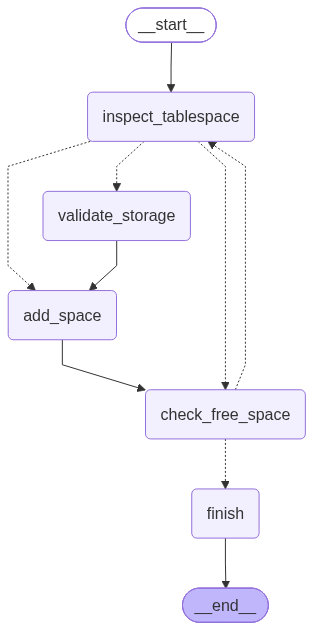

In [8]:
# 10. Set ending node and compile
builder.set_finish_point("finish")

graph = builder.compile()


# 11. Display graph
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization failed:", e)

In [9]:
# 12. Input data
initial_state: TablespaceState = {
    "tablespace_name": "USERS",
    "free_space_gb": 5,
    "required_free_space_gb": 15,
    "increment_gb": 5,
    "storage_validated": False,
    "enough_space": False,
    "final": "",
}


In [10]:
# Prevent a non-increasing loop

if initial_state["increment_gb"] <= 0:
    raise ValueError("increment_gb must be greater than zero.")


# 13. Run graph
result = graph.invoke(initial_state)


# 14. Display final output
print("\nFinal Output:")
print(result["final"])


Checking USERS: 5 GB free
Storage validation completed.
Added 5 GB. Available free space: 10 GB
More free space is needed.

Checking USERS: 10 GB free
Added 5 GB. Available free space: 15 GB
Required free space is available.

Final Output:
Tablespace USERS has 15 GB free. Required: 15 GB. Simulation completed.
